# Analysis of Rhythmic Activity in an Invasive ECoG Dataset
## 2nd part case study
### lecturer: Conrado A. Bosman

## Introduction
In this tutorial, we continue the case study from the previous session, now focusing on **windowing (tapers), zero padding, and the multitaper method** for spectral estimation. We will work with a one-second segment of invasive ECoG from a patient with intractable epilepsy, sampled at 500 Hz.

**Premise**

- A patient with intractable epilepsy is being evaluated for resective surgery.
- As part of the clinical workup, electrodes are implanted directly on the cortical surface (ECoG).
- We receive a **1 s ECoG segment** recorded from a single electrode at **500 Hz** sampling rate.
- Data quality is good and free of obvious artifacts.

**Aims of this tutorial**

- Characterize the rhythms present in this ECoG segment.
- Understand how our **estimation choices** (rectangular vs Hanning taper, zero padding, multitaper) shape the observed spectrum.
- Learn how multitaper estimation can reveal additional spectral structure (e.g. gamma band).

## Visual inspection of the data

As in the previous tutorial, we start by loading the ECoG data (`Ch4-ECoG-1.mat`), plotting voltage versus time, and visually inspecting the signal for rhythmic activity. The data required for this tutorial and its exercises are in the subfolder `chapter4_Data`. Download the ZIP file from Canvas and unzip it **in the same directory as this notebook**.\
The first cell imports the packages needed for this tutorial. The next one load and plot the data:

In [2]:
# Core numerical + plotting
import numpy as np
import matplotlib.pyplot as plt

# I/O for the .mat files 
from scipy.io import loadmat
from pathlib import Path

# Statistics (for confidence intervals on the spectrum)
from scipy.stats import chi2

# Spectral analysis tools (multitaper etc.)
import nitime.algorithms.spectral as spectrum

# Set plotting defaults
plt.rcParams['figure.figsize'] = (8, 4)
plt.rcParams['font.size'] = 12
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.grid"] = True

Sampling frequency: 500.0 Hz, duration: 1.000 s


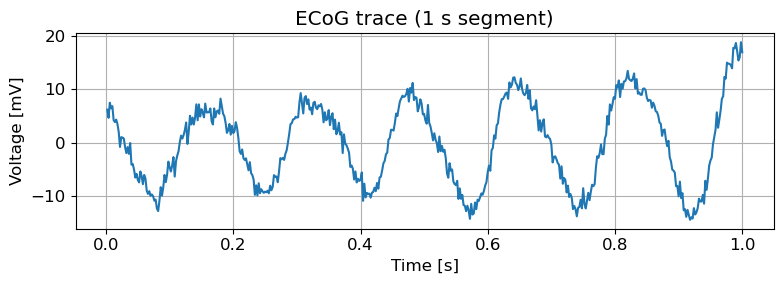

In [8]:
# Base directory = folder where this notebook lives
base_dir = Path().resolve()

data_file = base_dir / "chapter4_Data" / "Ch4-ECoG-1.mat"

# Load MATLAB file
mat = loadmat(data_file)  

t = mat["t"].squeeze()       # time vector
ecog = mat["ECoG"].squeeze() # ECoG signal (in mV)

dt = t[1] - t[0]
fs = 1.0 / dt

print(f"Sampling frequency: {fs:.1f} Hz, duration: {t[-1]:.3f} s")

plt.figure(figsize=(8, 3))
plt.plot(t, ecog)
plt.xlabel("Time [s]")
plt.ylabel("Voltage [mV]")
plt.title("ECoG trace (1 s segment)")
plt.tight_layout()
plt.show()

**Task:** Describe in 2-3 sentences what you see in the trace. Is there clear rhythmic activity? If so, at which frequency (Hz)?

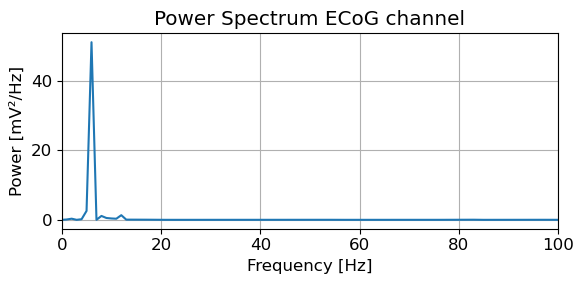

In [9]:
# Remove mean
x = ecog - np.mean(ecog)

# Basic spectral parameters
dt = t[1] - t[0]
fs = 1.0 / dt
T = t[-1]             # duration; here T ≈ 1 s if t starts at dt
N = len(x)

# Fourier transform and power spectrum
xf = np.fft.fft(x)
Sxx = 2 * (dt**2) / T * (xf * np.conj(xf))   # Normalization procedure
Sxx = Sxx[:N//2 + 1]                         # keep non-negative frequencies

# Frequency axis
fNQ = fs / 2
faxis = np.linspace(0, fNQ, len(Sxx))        # faxis here is calculated using linspace
                                             # linspace gives evenly spaced numbers over a range
plt.figure(figsize=(6, 3))
plt.plot(faxis, Sxx.real)
plt.xlim(0, 100)
plt.xlabel("Frequency [Hz]")
plt.ylabel("Power [mV²/Hz]")
plt.title("Power Spectrum ECoG channel")
plt.tight_layout()
plt.show()

**Task**: What could you say about the power spectrum? Write a comment in the cell below

As we saw previously, a `log–log` representation can help reveal structures that might otherwise go unnoticed.

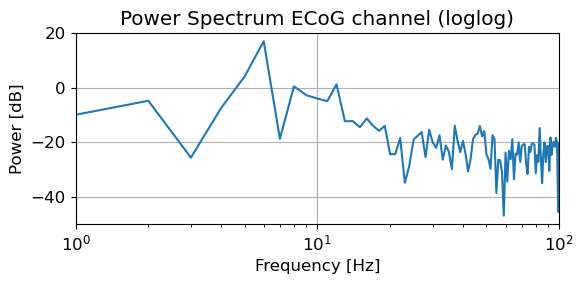

In [12]:
plt.figure(figsize=(6, 3))
plt.semilogx(faxis, 10 * np.log10(Sxx.real))
plt.xlim(1, 100)
plt.ylim(-50,20)
plt.xlabel("Frequency [Hz]")
plt.ylabel("Power [dB]")
plt.title("Power Spectrum ECoG channel (loglog")
plt.tight_layout()
plt.show()

The `log–log` plot confirms that, in addition to the prominent peak around 6 Hz, there is a structure centered near 10 Hz. A closer look suggests this may actually be a double-peak. However, with our current spectral estimate, we cannot clearly disentangle whether this is a genuine structure or an artifact of the way we computed the power spectrum. To address this question, we need to consider the role of **windowing** in spectral estimation.

## The rectangular taper and convolution

When we observe only a finite time segment of a signal (here, 1 s), we are multiplying the (hypothetical) infinite signal by a **rectangular window**.

- In the **time domain**, the window just selects the interval we observe.
- In the **frequency domain**, multiplication by a window becomes **convolution** with the window’s own spectrum.

The rectangular window has a broad main lobe and strong side lobes in frequency. This is what causes **spectral leakage** and the “wiggly” peaks we see.

*This concept will be discussed in length in the PDF attached to this notebook. The code displayed in the PDF is transcribed below.*

### Quick convolution theorem demo 


In [20]:
# Simple demonstration of the convolution theorem

x = np.array([3, 4, 5, 6], dtype=float)
w = np.array([-1, 0.1, -0.2, 1], dtype=float)

# Convolution in time, then FFT
a = np.fft.fft(np.convolve(w, x))

# Product of FFTs (after zero padding to same length)
L = len(x) + len(w) - 1
w_pad = np.pad(w, (0, L - len(w)))
x_pad = np.pad(x, (0, L - len(x)))
b = np.fft.fft(w_pad) * np.fft.fft(x_pad)

print("Are the FFTs (a and b) approximately the same? ",
      np.allclose(a, b))


Are the FFTs (a and b) approximately the same?  True


### Convolution theorem in action: windowing a sinusoid

Here we illustrate the convolution theorem in the context of spectral estimation:

- $x(t)$ is a pure 10 Hz sinusoid.
- $w(t)$ is a 1-second **rectangular window** (0–1 s, then 0).
- The observed signal is the product $x(t)\,w(t)$: we only "see" the sinusoid during the 1 s window.

Recall the convolution theorem:

$$
\mathcal{F}\{x(t)\,w(t)\}(f) = X(f) * W(f),
$$

i.e. **multiplication in time** becomes **convolution in frequency**.

Below, you see a demonstration of the effect:

![recTapecartoon](chapter4_Data/rect_tape_demo.png)


From the plots:

- $|X(f)|$ is sharply concentrated near 10 Hz (as expected for a pure sinusoid).
- $|W(f)|$ has a broad main lobe and strong side lobes (the sinc-like spectrum of the rectangular window).
- $|\mathcal{F}\{x(t)\,w(t)\}(f)|$ is **no longer a sharp line at 10 Hz** but a smeared-out bump: the 10 Hz component has been convolved with the window’s broad spectrum.

This is exactly the **spectral leakage** problem we encounter with finite-length recordings. The “rectangular taper” in time spreads narrow-band energy across neighboring frequencies.

### From window length to zero padding

So far we have seen that the **duration of the rectangular taper** directly controls the frequency resolution and leakage of our estimate: shorter windows spread energy across a broader range of frequencies, while longer windows give narrower main lobes in $|W(f)|$ and sharper peaks in the spectrum.

A natural question is: *what if we “increase the window size” not by collecting more data, but by simply adding zeros to our signal?* In other words, can we improve frequency resolution just by **zero padding** the same 0.5 s (or 1 s) of data so that the FFT “thinks” it sees a longer segment? In the next example we will compare spectra **with and without zero padding**, and then contrast them with a true long recording, to see what zero padding really does—and what it cannot do.

#### Intermezzo: Task – Interpreting the Python code

Below, you find the Python code used to generate the figure. The code is **slightly more complex** than what we usually write in this course, but it is a good opportunity to practice reading and understanding real analysis scripts.

> **Your task:** Provide a written explanation (in your own words) of what the code does, step by step.

Use the following guiding questions:

1. **Signal construction**
   - How is the time axis defined?
   - How are the sinusoidal components (at two different frequencies) generated?
   - How is the “short segment” extracted from the long signal?

2. **Power spectrum function**
   - What does the function `power_spectrum(x, fs, nfft=None)` do?
   - What is the role of `nfft` and how does it control **zero padding**?
   - Why do we only keep the first half of the spectrum (`[:nfft//2 + 1]`)?

3. **Zero padding vs no padding**
   - For the short segment, what is the difference between calling `power_spectrum` **with** and **without** the `nfft` argument?
   - How does this relate to the frequency axis `f_short` vs `f_short_pad`?

4. **Long segment**
   - How is the power spectrum of the long (10 s) signal computed?
   - How does the longer duration change the frequency resolution $\Delta f$ compared to the short one?

5. **Plotting**
   - How are the different spectra (short/no padding, short/padded, long/no padding) combined in the figure?
   - What does each line in the two panels represent, and how does the code encode this?

Write your explanation in a short paragraph (8–12 sentences). Focus on the **logic** of the code (what happens and why), rather than line-by-line details. The goal is to show that you understand how Python executes this analysis from raw time series to the final spectral plots.



Short segment duration: 0.5 s
Frequency resolution short: Δf = 2.00 Hz
Long segment duration: 10.00 s
Frequency resolution long: Δf = 0.10 Hz


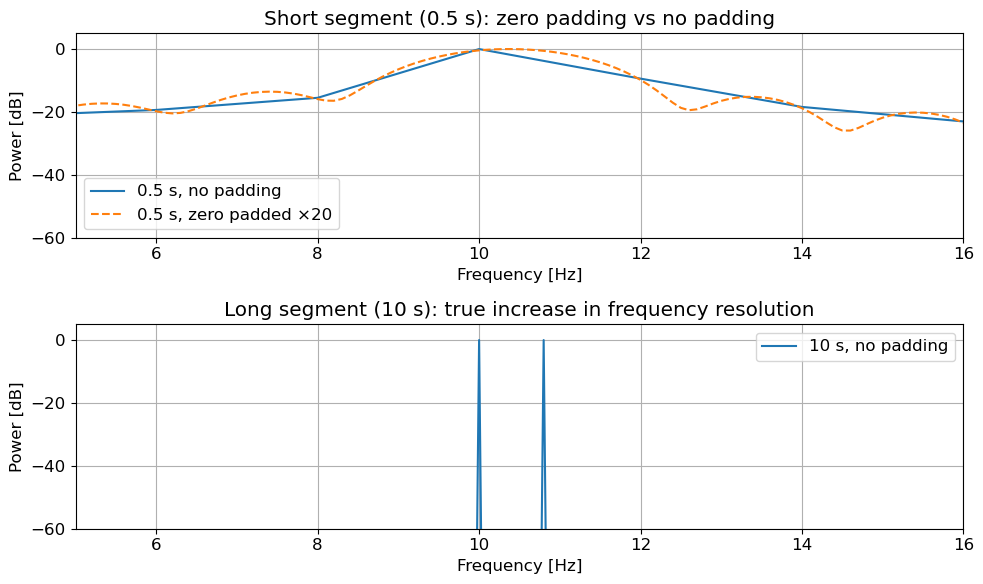

In [30]:
# -------------------------
# Settings
# -------------------------
Fs = 500.0
dt = 1.0 / Fs

f1 = 10.0    # first frequency (Hz)
f2 = 10.8    # second frequency (Hz) - closer than 1 / 0.5 s = 2 Hz

# Long signal: 10 seconds
t_long = np.arange(0, 10.0, dt)
x_long = np.sin(2 * np.pi * f1 * t_long) + np.sin(2 * np.pi * f2 * t_long)

# Short segment: 0.5 seconds
T_short = 0.5
N_short = int(T_short * Fs)
t_short = t_long[:N_short]
x_short = x_long[:N_short]

print(f"Short segment duration: {T_short} s")
print(f"Frequency resolution short: Δf = {1/T_short:.2f} Hz")

def power_spectrum(x, fs, nfft=None):
    """
    Simple single-segment power spectrum (one-sided).
    Returns frequency axis and PSD (not yet in dB).
    """
    x = np.asarray(x, float)
    x = x - x.mean()
    N = len(x)
    dt = 1.0 / fs

    if nfft is None:
        nfft = N

    T = N * dt
    X = np.fft.fft(x, n=nfft)
    Sxx = 2 * (dt**2) / T * (X * np.conj(X))
    Sxx = Sxx[:nfft//2 + 1].real
    faxis = np.linspace(0, fs/2, len(Sxx))
    return faxis, Sxx

def to_db(P):
    """
    Convert power to dB, normalized so max = 0 dB.
    """
    eps = 1e-24
    return 10 * np.log10((P + eps) / P.max())

# Short segment: no padding
f_short, P_short = power_spectrum(x_short, Fs)

# Short segment: heavy zero padding (e.g. 20x)
pad_factor = 20
f_short_pad, P_short_pad = power_spectrum(x_short, Fs, nfft=pad_factor * len(x_short))

# Long signal: 10 s, no padding
T_long = t_long[-1] - t_long[0] + dt
print(f"Long segment duration: {T_long:.2f} s")
print(f"Frequency resolution long: Δf = {1/T_long:.2f} Hz")

f_long, P_long = power_spectrum(x_long, Fs)

# Convert to dB
P_short_db = to_db(P_short)
P_short_pad_db = to_db(P_short_pad)
P_long_db = to_db(P_long)

# -------------------------
# Plot
# -------------------------
plt.figure(figsize=(10, 6))

# Short, no padding
plt.subplot(2, 1, 1)
plt.plot(f_short, P_short_db, label="0.5 s, no padding")
plt.plot(f_short_pad, P_short_pad_db, "--", label=f"0.5 s, zero padded ×{pad_factor}")
plt.xlim(5, 16)
plt.ylim(-60, 5)
plt.xlabel("Frequency [Hz]")
plt.ylabel("Power [dB]")
plt.title("Short segment (0.5 s): zero padding vs no padding")
plt.legend()

# Long, no padding
plt.subplot(2, 1, 2)
plt.plot(f_long, P_long_db, label="10 s, no padding")
plt.xlim(5, 16)
plt.ylim(-60, 5)
plt.xlabel("Frequency [Hz]")
plt.ylabel("Power [dB]")
plt.title("Long segment (10 s): true increase in frequency resolution")
plt.legend()

plt.tight_layout()
plt.show()


Now, we can continue with the explanation of the effect of **zero padding** vs the use of more data:

#### Zero padding vs more data: what really improves resolution?

Here we simulate a signal that is the sum of **two sinusoids at 10 Hz and 10.8 Hz**, sampled at 500 Hz:

- First, we take only **0.5 s** of data.
- Then, we also consider the full **10 s** recording.

For the 0.5 s segment:

- The frequency resolution is  
  $
  \Delta f = \frac{1}{T} = \frac{1}{0.5} = 2\ \text{Hz}.
  $
- Our two frequencies (10 and 10.8 Hz) are **closer than** $\Delta f$.
- In the top panel:
  - The **solid line** is the spectrum of 0.5 s with **no padding**.
  - The **dashed line** is the spectrum of the *same* 0.5 s segment with heavy **zero padding** (FFT length ≫ number of samples).

What do we see?

- Zero padding makes the peak around 10–11 Hz **smoother** and adds more sample points on the curve.
- However, it **does not separate** the 10 Hz and 10.8 Hz components: there is still just **one broad bump**, because the true resolution is limited by $T = 0.5$ s.

For the 10 s segment:

- The frequency resolution is  
  $
  \Delta f = \frac{1}{10} = 0.1\ \text{Hz}.
  $
- Now the two frequencies (10 and 10.8 Hz) are **well separated** compared to $\Delta f$.
- In the bottom panel (10 s, no padding), we clearly see **two distinct peaks** near 10 Hz and 10.8 Hz.

**Take-home message**

- **Zero padding** changes the *sampling* of the spectrum (it interpolates between existing FFT bins), so peaks look smoother and the frequency axis is more finely spaced.
- **Zero padding does *not* improve true frequency resolution**: if two components are closer than $1/T$, you cannot reliably separate them, no matter how much zero padding you use.
- To genuinely improve resolution, you need **more data** (larger $T$), not just more zeros.

### Beyond the rectangular taper: introducing the Hann window

We have now seen that the **rectangular taper** has a spectrum with a broad main lobe and strong side lobes, which leads to substantial spectral leakage. Shortening the window makes this even worse in the frequency domain, and zero padding does not solve the underlying problem—it only interpolates the existing spectrum.

A natural next step is to ask whether we can choose a **smoother taper in time** whose spectrum has **smaller side lobes**, so that it spreads energy less aggressively to neighboring frequencies. One of the most common choices is the **Hann (Hanning) window**. Before comparing spectra, it is useful to look at the shape of the Hann taper itself and contrast it with the rectangular window.


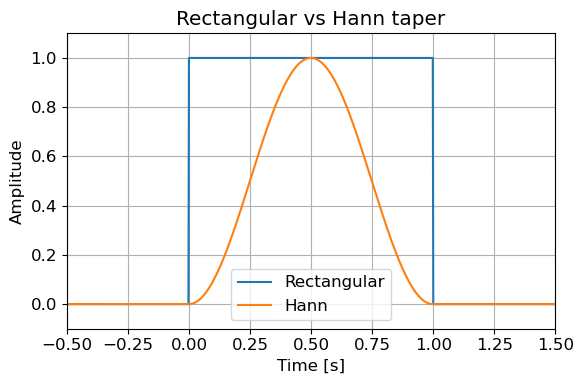

In [34]:
# We already have ecog and fs from before
N = len(ecog)
dt = 1.0 / fs
T_seg = N * dt

# Extended time axis: from -0.5 s to 1.5 s, step = dt
t_ext = np.arange(-0.5, 1.5, dt)

# Initialize extended windows with zeros
rect_ext = np.zeros_like(t_ext)
hann_ext = np.zeros_like(t_ext)

# Indices where the window is "active": between 0 and T_seg
active = (t_ext >= 0) & (t_ext <= T_seg)

# Define tapers
# Rectangular window: 1 between 0 and T_seg
rect_ext[active] = 1.0

# Hann window: Hann shape between 0 and T_seg, 0 outside
hann_ext[active] = np.hanning(active.sum())

plt.figure(figsize=(6, 4))
plt.plot(t_ext, rect_ext, label="Rectangular")
plt.plot(t_ext, hann_ext, label="Hann")
plt.xlim(-0.5, 1.5)
plt.ylim(-0.1, 1.1)
plt.xlabel("Time [s]")
plt.ylabel("Amplitude")
plt.title("Rectangular vs Hann taper")
plt.legend()
plt.tight_layout()
plt.show()


In the `loglog` version of the power spectrum of the ECoG channel, we saw a hint of activity around **10 Hz** and wondered whether this was a genuine feature of the patient's spectrum or an artifact introduced by the rectangular window.

To address this, we now apply a **Hann (Hanning) taper**, which has a smoother shape in time and much smaller side lobes in frequency. The next figure compares the original **raw** ECoG trace with the same data multiplied by the Hann taper, and shows the two-sided power spectra of the rectangular and Hann tapers. The tapers are zero-padded before taking the FFT, not to increase resolution, but to obtain a smoother view of their theoretical spectra and make the side lobes clearly visible.

![RecHann_comp](chapter4_Data/hanning_vs_rect.png)

Below you find the code used to calculate the power spectrum of the data, first with a rectangular taper (as we did above, but note the slightly different implementation), and then with a Hann taper.


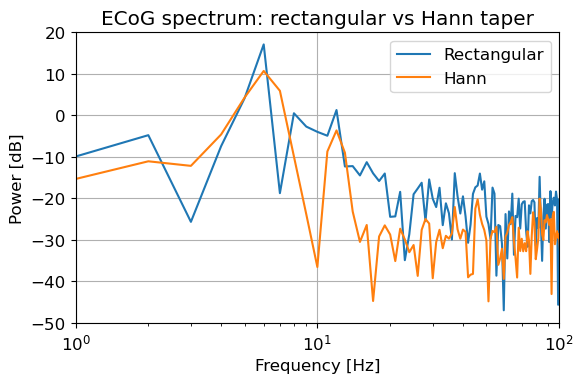

In [40]:
def one_segment_psd(x, fs, window=None, nfft=None):
    """
    Single-segment power spectrum estimate (one-sided).

    Parameters
    ----------
    x      : 1D array
        Time series.
    fs     : float
        Sampling frequency (Hz).
    window : 1D array or None
        Optional taper (same length as x). If None, use rectangular.
    nfft   : int or None
        FFT length (for zero padding). If None, use len(x).

    Returns
    -------
    f      : 1D array
        Frequency axis (Hz, 0..Nyquist).
    Sxx    : 1D array
        Power spectral density estimate.
    """
    x = np.asarray(x, float)
    N = len(x)
    dt = 1.0 / fs

    # Choose window (taper)
    if window is None:
        w = np.ones(N)
    else:
        w = np.asarray(window, float)
        assert len(w) == N, "Window length must match data length."

    # Demean and apply window
    xw = (x - x.mean()) * w

    # FFT length
    if nfft is None:
        nfft = N

    # ONE-SIDED FFT, consistent with previous examples
    X = np.fft.rfft(xw, n=nfft)

    # Same normalization as before
    T = N * dt
    Sxx = 2 * (dt**2) / T * (X * np.conj(X))   # complex-valued, real on real data
    Sxx = Sxx.real

    # Frequency axis
    f = np.fft.rfftfreq(nfft, d=dt)
    return f, Sxx

# --- Windows ---
N = len(ecog)
rect_window = np.ones(N)
hann_window = np.hanning(N)   # keep the taper generation simple and explicit

# --- PSDs ---
f_rect, P_rect = one_segment_psd(ecog, fs, window=rect_window)
f_hann, P_hann = one_segment_psd(ecog, fs, window=hann_window)

# --- Plot ---
plt.figure(figsize=(6, 4))
plt.semilogx(f_rect, 10 * np.log10(P_rect), label="Rectangular")
plt.semilogx(f_hann, 10 * np.log10(P_hann), label="Hann")
plt.xlim(1, 100)
plt.ylim(-50, 20)
plt.xlabel("Frequency [Hz]")
plt.ylabel("Power [dB]")
plt.legend()
plt.title("ECoG spectrum: rectangular vs Hann taper")
plt.tight_layout()
plt.show()

#### Task – Interpreting the tapered spectra

Look carefully at the figure comparing the power spectra obtained with a **rectangular** taper and with a **Hann** taper.

1. **Describe the figure**
   - How does the overall shape of the spectrum look in each case?
   - How are the peaks around **6 Hz** and **10 Hz** represented with the rectangular taper?
   - How do these same peaks appear when using the Hann taper (height, width, separation, background noise level)?

2. **Conclusions about the two peaks**
   - Based on the comparison, do you consider the **10 Hz** component a genuine feature of the signal or more likely an artifact of the rectangular taper? Justify your answer.
   - How does the use of the Hann taper change your confidence in the presence of **two distinct rhythms** (around 6 Hz and 10 Hz) in this ECoG channel?

Write your answer in a short paragraph (5–8 sentences), explicitly referring to what you see in the two spectra.


### Beyond the Hann taper: the Multitaper method

So far, we have seen how changing from a **rectangular** taper to a **Hann** taper can reduce spectral leakage: the Hann window trades a slightly wider main lobe for much smaller side lobes, making peaks like the 6 Hz and 10 Hz rhythms easier to distinguish. However, any single taper still gives us only **one** estimate of the spectrum from our finite 1 s data segment, and that estimate will always contain some noise and bias.

The **multitaper method** goes one step further. Instead of using just one window, we apply **multiple, carefully designed tapers** to the *same* data segment. These tapers are discrete portions of the **prolate spheroidal sequences** (also called Slepian sequences), which are constructed to provide several **independent estimates** of the underlying spectrum with a controlled time–frequency trade-off. Each taper produces its own power spectrum; the final multitaper estimate is obtained by **averaging** across all these tapered spectra.

This has two important consequences:

- It **reduces variance** in the spectral estimate, because we average multiple independent realizations computed from the same data.
- It allows us to **tune the balance** between frequency resolution and variance: if we can tolerate coarser frequency resolution (wider peaks), we can use more tapers and obtain a smoother, less noisy spectrum.

In practice, we choose a **time–bandwidth product** $(TW)$, which sets the desired resolution bandwidth $(2W)$ for a given data length $(T)$. A common rule of thumb is that we can use up to about $(K \approx 2TW - 1)$ tapers. In our 1 s ECoG example, if we accept a resolution of about 6 Hz (so $(2W = 6)$ Hz and $(TW = 3)$), this yields $(K = 5)$ useful tapers. 

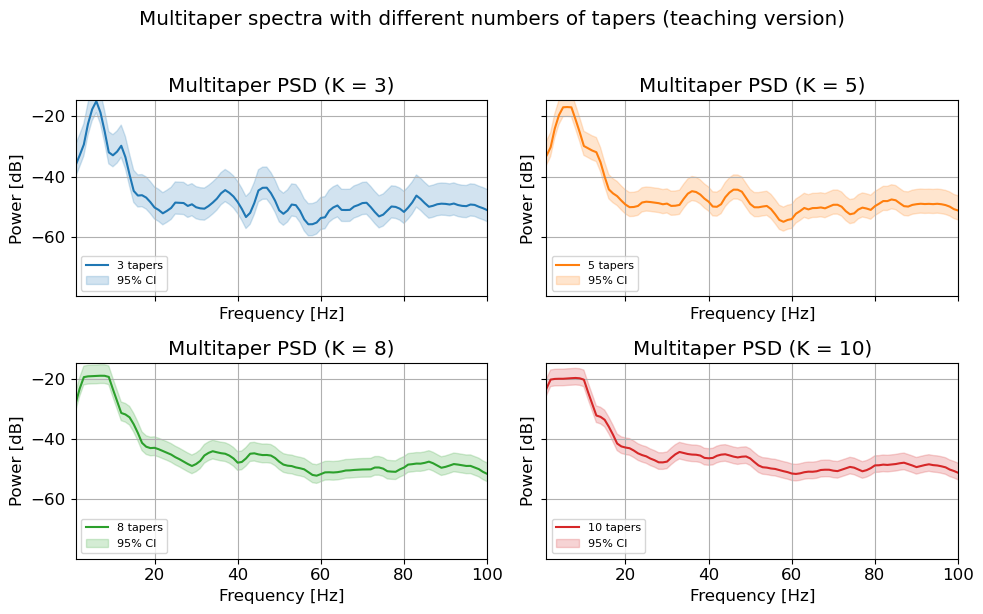

In [41]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal.windows import dpss
from scipy.stats import chi2
from scipy.ndimage import uniform_filter1d

def multitaper_psd_ci_teaching(x, fs, TW, Kmax=None, alpha=0.05):
    """
    Multitaper power spectrum with simple chi-square confidence intervals.
    Teaching version:
      - no zero padding (nfft = len(x))
      - one-sided PSD

    Parameters
    ----------
    x     : 1D array
        Time series (e.g. 1 s of ECoG).
    fs    : float
        Sampling frequency (Hz).
    TW    : float
        Time–bandwidth product.
    Kmax  : int or None
        Number of tapers to use. If None, use K = 2*TW - 1 (rounded).
    alpha : float
        1 - confidence level (alpha = 0.05 -> 95% CI).

    Returns
    -------
    f       : frequency axis (Hz, one-sided)
    psd     : multitaper PSD (linear units)
    ci_low  : lower CI bound
    ci_high : upper CI bound
    """
    x = np.asarray(x, float)
    x = x - x.mean()
    N = len(x)
    dt = 1.0 / fs

    # Number of tapers
    if Kmax is None:
        Kmax = int(2 * TW - 1)

    nfft = N  # no zero padding for teaching version

    # DPSS tapers: shape (Kmax, N)
    tapers = dpss(N, TW, Kmax)

    # Apply tapers and compute FFTs
    Xk = np.fft.fft(tapers * x, n=nfft, axis=1)  # shape: (Kmax, nfft)
    T = N * dt
    Sxx_k = 2 * (dt**2) / T * (Xk * np.conj(Xk))  # PSD per taper
    Sxx_k = Sxx_k[:, :nfft//2 + 1].real          # one-sided

    # Average across tapers
    psd = Sxx_k.mean(axis=0)

    # Frequency axis
    f = np.linspace(0, fs/2, psd.size)

    # Degrees of freedom (approx) for multitaper: 2*K
    nu = 2 * Kmax

    # Chi-square CI:
    # psd * nu / chi2_{1-alpha/2, nu} <= true PSD <= psd * nu / chi2_{alpha/2, nu}
    chi2_low = chi2.ppf(alpha/2, nu)
    chi2_high = chi2.ppf(1 - alpha/2, nu)

    ci_low = psd * nu / chi2_high
    ci_high = psd * nu / chi2_low

    return f, psd, ci_low, ci_high

# -------------------------------------------------------------------
# Multitaper spectra for different numbers of tapers (teaching figure)
# -------------------------------------------------------------------

x = ecog            # 1 s ECoG segment
K_list = [3, 5, 8, 10]
colors = ['C0', 'C1', 'C2', 'C3']

fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True, sharey=True)
axes = axes.ravel()

for ax, K, col in zip(axes, K_list, colors):
    # Choose TW so that K ≈ 2*TW - 1 -> TW ≈ (K+1)/2
    TW = (K + 1) / 2

    f, psd, ci_low, ci_high = multitaper_psd_ci_teaching(x, fs, TW=TW, Kmax=K)

    # Convert to dB
    eps = 1e-24
    psd_db = 10 * np.log10(psd + eps)
    ci_low_db = 10 * np.log10(ci_low + eps)
    ci_high_db = 10 * np.log10(ci_high + eps)

    # --- small smoothing ONLY for plotting (3-point moving average) ---
    psd_db_s = uniform_filter1d(psd_db, size=3)
    ci_low_db_s = uniform_filter1d(ci_low_db, size=3)
    ci_high_db_s = uniform_filter1d(ci_high_db, size=3)

    # Plot PSD
    ax.plot(f, psd_db_s, color=col, label=f"{K} tapers")

    # Plot CI as a ribbon
    ax.fill_between(f, ci_low_db_s, ci_high_db_s, color=col, alpha=0.2, label="95% CI")

    ax.set_xlim(1, 100)
    ax.set_ylim(psd_db_s.max() - 60, psd_db_s.max() + 5)
    ax.set_xlabel("Frequency [Hz]")
    ax.set_ylabel("Power [dB]")
    ax.set_title(f"Multitaper PSD (K = {K})")
    ax.legend(loc="lower left", fontsize=8)

fig.suptitle("Multitaper spectra with different numbers of tapers (teaching version)", y=1.02)
plt.tight_layout()
plt.show()


### Multitaper spectra with different numbers of tapers

This figure shows multitaper power spectra of the same 1 s ECoG segment, using **K = 3, 5, 8, 10** tapers. For each value of K:

- The solid line is the multitaper PSD in dB (one-sided, no zero padding).
- The shaded band indicates a **95% confidence interval**, based on a chi-square approximation with $2K$ degrees of freedom.

We apply a very small 3-point moving average **only for plotting** in order to reduce visual jitter; the underlying estimates are computed directly from the tapers without smoothing.

As K increases, the spectra become **visually smoother** and the confidence bands become **narrower**, reflecting the reduced variance from averaging over more tapers. However, the **frequency resolution** is still limited by the 1 s data segment: peaks at 6 Hz and 10 Hz remain relatively broad, and fine details beyond that time scale cannot be recovered by using more tapers alone. However, applying these tapers and averaging their spectra also reveals a weaker **gamma-band** component between 30 and 60 Hz, previously hidden in the noise.

## Summary

- We analyzed 1 s of ECoG data from an epilepsy patient using Fourier-based methods in **Python**.
- We computed the power spectrum and examined the effects of:
  - **Rectangular vs Hann taper** (leakage vs peak broadening),
  - **Zero padding** (smoother frequency axis without improved resolution),
  - **Multitaper estimation** (reduced variance at the cost of resolution).
- All methods indicated at least two clear frequency peaks near 6 and 10 Hz, and the multitaper method revealed an additional band between 30–60 Hz (gamma) that was largely hidden by noise in simpler estimates.
- This tutorial focused on building intuition: how our **estimation choices**, not just the data, shape what we see in the spectrum.
